# BIOT 6900 · Module 6, Part 2 — Applying a Real PRS to Real Genotypes

**Worked example · run and read · not graded.** In Part 1 you built a PRS by hand on invented data. Here you run the *same* workflow as a real analyst would: take a **published Alzheimer's score from the PGS Catalog**, apply it to **real 1000 Genomes genotypes**, and ask the question that the toy model could not, does the score work equally well across ancestry groups?

> **Data.** The notebook looks for the real files in a `data/` folder (posted on Canvas): a 1000 Genomes genotype subset, a variant table giving each variant's REF and ALT allele, the PGS Catalog scoring file, and super-population labels. If they are absent it falls back to a clearly-labelled **synthetic demo cohort** so the notebook always runs in class. The workflow is identical either way.

> ⚠️ **The phenotype is simulated.** 1000 Genomes has genotypes and ancestry but no disease labels. The PRS itself and its distribution across ancestries are computed on **real** inputs; only the case/control label used for AUC and calibration is simulated, and it is labelled as such. Treat those numbers as illustrative of a real phenomenon.

Nothing to complete here. Run top to bottom (**Kernel → Restart & Run All**) and read the outputs.

## 0. Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm
from sklearn.metrics import roc_auc_score
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score

NU_RED, NU_COOL, NU_GREY = "#C8102E", "#1E2028", "#6E7178"
POP_COLORS = {"EUR":"#1E2028","AFR":"#C8102E","EAS":"#6E7178","SAS":"#A4804A","AMR":"#9AA0A6"}
rng = np.random.default_rng(6900)

## 1. Load the data

`load_data()` returns four tidy tables: **geno** (dosages 0/1/2 counting the **ALT** allele, people × variants), **variants** (`variant`, `ref`, `alt`), **score** (the PGS Catalog file: `variant`, `effect_allele`, `other_allele`, `weight`), and **meta** (`ancestry`, `age`, and the simulated `phenotype`). You do not need to edit this cell.

In [2]:
def _make_demo_cohort(seed=6900):
    """SYNTHETIC stand-in for 1000 Genomes + a PGS Catalog score. Phenotype is
    SIMULATED from hidden causal variants; the published weights tag those causals
    well in EUR, worse elsewhere -> a real portability drop. Allele frequencies
    differ by population (more drift away from EUR, and APOE-e4-like frequencies
    for the large-effect variant), so the PRS distribution shifts by ancestry."""
    r = np.random.default_rng(seed)
    #        n,  tagging (LD) with causal, allele-frequency drift
    pops = {"EUR":(600,0.92,0.05),"AFR":(600,0.40,0.15),"EAS":(500,0.58,0.12),
            "SAS":(500,0.66,0.09),"AMR":(500,0.55,0.07)}
    apoe_freq = {"EUR":0.14,"AFR":0.22,"EAS":0.09,"SAS":0.09,"AMR":0.11}   # roughly e4 frequencies
    M = 80
    b = r.normal(0, 0.15, M); b[0] = 1.3
    w = b * 0.92
    base = r.uniform(0.15, 0.5, M)
    Gt, Gc, anc, ages = [], [], [], []
    for pop,(n,rho,drift) in pops.items():
        f = np.clip(base + r.normal(0,drift,M), 0.03, 0.97); f[0] = apoe_freq[pop]; thr = norm.ppf(f)
        gc = np.zeros((n,M)); gt = np.zeros((n,M))
        for _ in range(2):
            L = r.normal(size=(n,M)); Z = r.normal(size=(n,M))
            gc += (L<thr); gt += ((rho*L + np.sqrt(1-rho**2)*Z) < thr)
        Gt.append(gt); Gc.append(gc); anc += [pop]*n; ages.append(r.normal(60,8,n))
    Gt = np.vstack(Gt); Gc = np.vstack(Gc); anc = np.array(anc); age = np.concatenate(ages)
    lin = Gc @ b + 0.03*(age-60); b0 = np.log(0.30/0.70) - lin.mean()
    y = (r.uniform(size=len(lin)) < 1/(1+np.exp(-(b0+lin)))).astype(int)
    v = [f"rs_tag_{i:03d}" for i in range(M)]
    # Real nucleotides. As in real scoring files, some rows report the REF allele as the
    # effect allele (with the weight's sign reversed), so harmonization has work to do.
    nts = np.array(list("ACGT"))
    ref = r.choice(nts, M); alt = np.array([r.choice(nts[nts != x]) for x in ref])
    eff_is_ref = r.random(M) < 0.25
    return (pd.DataFrame(Gt, columns=v),
            pd.DataFrame({"variant":v, "ref":ref, "alt":alt}),
            pd.DataFrame({"variant":v, "effect_allele":np.where(eff_is_ref, ref, alt),
                          "other_allele":np.where(eff_is_ref, alt, ref),
                          "weight":np.where(eff_is_ref, -w, w)}),
            pd.DataFrame({"ancestry":anc, "age":age, "phenotype":y}))

def load_data(path="data"):
    import os
    need = ["genotypes.csv","variants.csv","score.csv","meta.csv"]
    if all(os.path.exists(os.path.join(path,f)) for f in need):
        geno, variants, score, meta = (pd.read_csv(os.path.join(path,f)) for f in need)
        print("Loaded REAL data from", path)
    else:
        print("="*64); print("  NO real data in ./data  ->  SYNTHETIC demo cohort")
        print("  PRS and ancestry structure are modelled; phenotype is SIMULATED."); print("="*64)
        geno, variants, score, meta = _make_demo_cohort()
    print(f"people={len(meta)}  score variants={score.shape[0]}  cases={100*meta.phenotype.mean():.0f}%")
    return geno, variants, score, meta

geno, variants, score, meta = load_data()

  NO real data in ./data  ->  SYNTHETIC demo cohort
  PRS and ancestry structure are modelled; phenotype is SIMULATED.
people=2700  score variants=80  cases=33%


## 2. The score we are applying

A PGS Catalog score is just a list of variants, each with an effect allele and a weight (per-allele log-odds). The one we use was trained in **European-ancestry** samples, like most published scores, which is the root of the portability problem we are about to see.

In [3]:
print(f"The score has {score.shape[0]} variants.")
score.head()

The score has 80 variants.


,variant,effect_allele,other_allele,weight
0,rs_tag_000,T,A,-1.196000
1,rs_tag_001,C,T,-0.120191
2,rs_tag_002,T,G,-0.161993
3,rs_tag_003,A,C,0.264696
4,rs_tag_004,T,A,-0.019441


## 3. Harmonize and compute the PRS

Line the score up with the genotype columns, then make sure each weight is applied to the allele it belongs to. The genotype dosages count the **ALT** allele, so for each variant compare the score's `effect_allele` with that variant's REF and ALT:

- effect allele = **ALT** → use the dosage as it is;
- effect allele = **REF** → **flip** the dosage (`2 − dosage`), so it counts the effect allele;
- effect allele is **neither** (for example a strand mismatch) → **drop** the variant and report it.

Then the PRS is the same one line as Part 1.

In [4]:
shared = [v for v in score["variant"] if v in set(geno.columns) & set(variants["variant"])]
s  = score.set_index("variant").loc[shared]
va = variants.set_index("variant").loc[shared]
eff = s["effect_allele"].str.upper()
same = (eff == va["alt"].str.upper()).to_numpy()     # effect allele is the counted (ALT) allele
flip = (eff == va["ref"].str.upper()).to_numpy()     # effect allele is REF -> count it with 2 - dosage
keep = same | flip
dropped = [v for v, k in zip(shared, keep) if not k]
shared, flip = [v for v, k in zip(shared, keep) if k], flip[keep]

G = geno[shared].to_numpy(dtype=float).copy()
w = s.loc[shared, "weight"].to_numpy()
G[:, flip] = 2 - G[:, flip]
print(f"variants used: {len(shared)}   flipped to effect allele: {int(flip.sum())}   "
      f"dropped (allele mismatch): {len(dropped)}")

prs = G @ w
prs_z = (prs - prs.mean()) / prs.std()
meta["prs"] = prs_z

variants used: 80   flipped to effect allele: 18   dropped (allele mismatch): 0


## 4. The real result: the PRS distribution shifts across ancestries

This panel uses **only real inputs** (genotypes and published weights); no phenotype is involved. Watch the distributions sit at different places. A single fixed "high-risk" percentile cutoff would therefore flag very different fractions of each group, before any mention of disease.

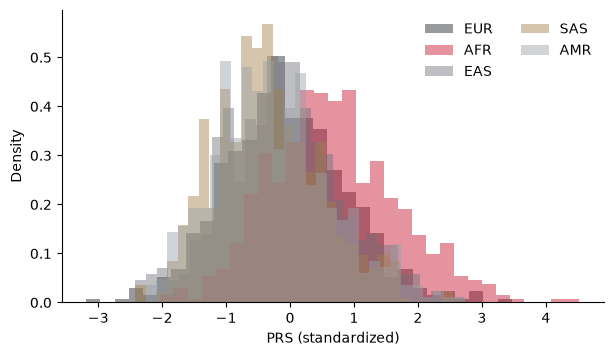

          mean PRS  % above top-10% cutoff
ancestry                                  
EUR          -0.06                     7.2
AFR           0.67                    23.5
EAS          -0.11                     7.2
SAS          -0.34                     4.0
AMR          -0.27                     6.0


In [5]:
fig, ax = plt.subplots(figsize=(7, 3.8))
for pop, c in POP_COLORS.items():
    ax.hist(meta.loc[meta.ancestry==pop,"prs"], bins=30, density=True, alpha=0.45, color=c, label=pop)
ax.set_xlabel("PRS (standardized)"); ax.set_ylabel("Density"); ax.legend(frameon=False, ncol=2)
for sp in ("top","right"): ax.spines[sp].set_visible(False)
plt.show()

cut = meta["prs"].quantile(0.90)                     # one "top 10%" cutoff for everyone
summary = pd.DataFrame({"mean PRS": meta.groupby("ancestry")["prs"].mean().round(2),
                        "% above top-10% cutoff": (100*(meta["prs"] > cut).groupby(meta["ancestry"]).mean()).round(1)})
print(summary.loc[list(POP_COLORS)])

## 5. Discrimination by ancestry (simulated phenotype)

Now bring in the simulated label to measure the AUC overall and within each group. Expect it highest in EUR and lower elsewhere: the portability penalty, because the European-derived weights tag the causal variants less well where the LD and allele frequencies differ.

Overall AUC: 0.614
  EUR: AUC = 0.682
  AFR: AUC = 0.567
  EAS: AUC = 0.532
  SAS: AUC = 0.561
  AMR: AUC = 0.557


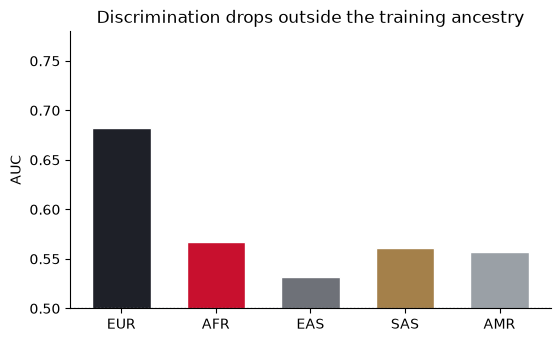

In [6]:
y = meta["phenotype"].to_numpy()
print(f"Overall AUC: {roc_auc_score(y, prs_z):.3f}")
aucs = {}
for pop in POP_COLORS:
    m = (meta.ancestry==pop).to_numpy()
    aucs[pop] = roc_auc_score(y[m], prs_z[m])
    print(f"  {pop}: AUC = {aucs[pop]:.3f}")

fig, ax = plt.subplots(figsize=(6.2, 3.6))
ax.bar(list(aucs), list(aucs.values()), color=[POP_COLORS[p] for p in aucs], width=0.62, edgecolor="white")
ax.axhline(0.5, color="#9AA0A6", ls=":", lw=1); ax.set_ylim(0.5, 0.78); ax.set_ylabel("AUC")
ax.set_title("Discrimination drops outside the training ancestry")
for sp in ("top","right"): ax.spines[sp].set_visible(False)
plt.show()

## 6. Calibration by ancestry

Discrimination asks whether the ranking is right; calibration asks whether the predicted probabilities are honest. Turn the PRS into a probability the way a published model would be built: fit it in the **training ancestry (EUR)** only, then apply that same model to everyone and compare predicted against observed risk **within each group**.

(Fitting and checking on the same pooled data would look well calibrated by construction, which tests nothing.)

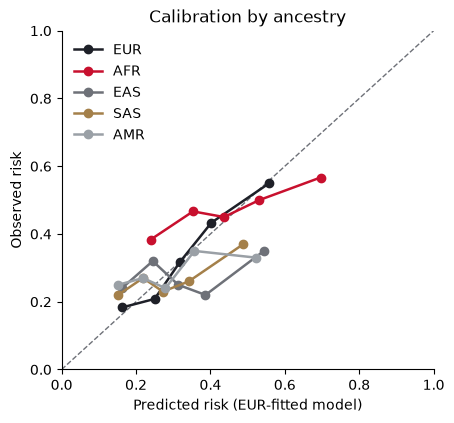

mean predicted vs observed risk:
  EUR: predicted 0.34   observed 0.34
  AFR: predicted 0.45   observed 0.47
  EAS: predicted 0.33   observed 0.28
  SAS: predicted 0.29   observed 0.27
  AMR: predicted 0.31   observed 0.29


In [7]:
def calibration_points(y, p, bins=5):
    edges = np.quantile(p, np.linspace(0,1,bins+1)); edges[-1] += 1e-9
    idx = np.clip(np.digitize(p, edges)-1, 0, bins-1)
    xs, ys = [], []
    for b in range(bins):
        m = idx==b
        if m.sum() > 5: xs.append(p[m].mean()); ys.append(y[m].mean())
    return np.array(xs), np.array(ys)

eur = (meta.ancestry=="EUR").to_numpy()
cal_model = LogisticRegression().fit(prs_z[eur].reshape(-1,1), y[eur])        # fitted in EUR only
p_hat = cal_model.predict_proba(prs_z.reshape(-1,1))[:,1]                      # applied to everyone

fig, ax = plt.subplots(figsize=(4.8, 4.4))
ax.plot([0,1],[0,1], ls="--", color=NU_GREY, lw=1)
for pop, c in POP_COLORS.items():
    m = (meta.ancestry==pop).to_numpy()
    xs, ys = calibration_points(y[m], p_hat[m])
    ax.plot(xs, ys, marker="o", color=c, lw=1.8, label=pop)
ax.set_xlabel("Predicted risk (EUR-fitted model)"); ax.set_ylabel("Observed risk"); ax.set_title("Calibration by ancestry")
ax.set_xlim(0,1); ax.set_ylim(0,1); ax.legend(frameon=False)
for sp in ("top","right"): ax.spines[sp].set_visible(False)
plt.show()

print("mean predicted vs observed risk:")
for pop in POP_COLORS:
    m = (meta.ancestry==pop).to_numpy()
    print(f"  {pop}: predicted {p_hat[m].mean():.2f}   observed {y[m].mean():.2f}")

## 7. Does the PRS add to simple clinical information?

Compare a model with **age only** to **age + PRS**, using cross-validated AUC. The gap is the incremental value of the score on top of something a clinic already knows.

In [8]:
age_z = ((meta["age"]-meta["age"].mean())/meta["age"].std()).to_numpy()
auc_age     = cross_val_score(LogisticRegression(), age_z.reshape(-1,1),        y, cv=5, scoring="roc_auc").mean()
auc_age_prs = cross_val_score(LogisticRegression(), np.column_stack([age_z,prs_z]), y, cv=5, scoring="roc_auc").mean()
print(f"AUC  age only:  {auc_age:.3f}")
print(f"AUC  age + PRS: {auc_age_prs:.3f}   (incremental value of the PRS)")

AUC  age only:  0.549
AUC  age + PRS: 0.620   (incremental value of the PRS)


## What this shows

- The PRS computes fine on real data, one line, exactly as in Part 1.
- Its **distribution shifts across ancestries** from real inputs alone, so a single threshold is not fair across groups.
- Its **discrimination is highest in the training ancestry** and lower elsewhere: the portability problem, quantified.
- A risk model **calibrated in EUR** is less honest when applied to other groups: the same score maps to different real risks.
- It adds some value over age alone, but the ceiling is modest, as expected for common disease.

**Next (Part 3, graded):** you run this entire workflow yourself, on a PGS Catalog score for your own Part I disease, and write up the portability, calibration, and clinical-utility questions.